# Lab 5.1 · Cascades and Simulations
**Chapter 5 · Social Network Analytics II — Information Diffusion**

**Goal:** measure real cascades, then simulate spread and compare seed strategies.
**Data:** `data/ev_cascades.csv` (repost events with parent IDs, timestamps in **UTC**, synthetic) · the karate club graph.

📖 Interactive study guide: [Chapter 5](https://mehrdadjalali-ai.github.io/SocialMediaAnayltics/interactive/Chapter5_Information_Diffusion.html) — includes a cascade builder and live IC / LT simulators.

In [1]:
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, OUTD = ROOT / "data", ROOT / "outputs"
OUTD.mkdir(exist_ok=True)
SEED = 42
import random, statistics as st
import pandas as pd, networkx as nx, matplotlib.pyplot as plt

## Walkthrough · rebuild cascades from parent IDs

In [2]:
c = pd.read_csv(DATA / "ev_cascades.csv", parse_dates=["timestamp"])
def cascade_metrics(g):
    T = nx.DiGraph(); T.add_nodes_from(g["post_id"])
    T.add_edges_from(g.dropna(subset=["parent_id"])[["parent_id", "post_id"]].values)
    root = g.loc[g["parent_id"].isna(), "post_id"].iloc[0]
    depth = nx.single_source_shortest_path_length(T, root)
    per_level = pd.Series(depth).value_counts()
    return pd.Series({"size": len(g), "depth": max(depth.values()),
                      "max_breadth": per_level.drop(0, errors="ignore").max(),
                      "duration_h": round((g["timestamp"].max() - g["timestamp"].min()).total_seconds() / 3600, 1),
                      "virality": round(nx.average_shortest_path_length(T.to_undirected()), 2)})
metrics = c.groupby("cascade_id").apply(cascade_metrics)
metrics

,size,depth,max_breadth,duration_h,virality
cascade_id,,,,,
c01,212.0,4.0,173.0,2.6,2.38
c02,38.0,19.0,3.0,13.5,8.49
c03,54.0,6.0,28.0,6.5,3.66
c04,95.0,4.0,79.0,2.4,2.37
c05,61.0,38.0,3.0,39.5,13.95
c06,43.0,4.0,19.0,2.2,3.38
c07,27.0,17.0,3.0,12.5,7.26
c08,18.0,2.0,15.0,1.1,2.08


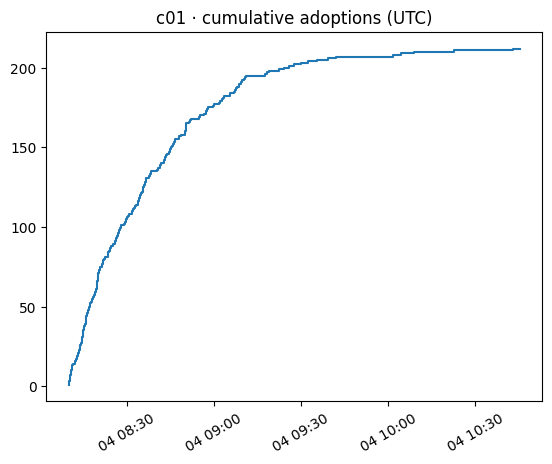

In [3]:
g = c[c.cascade_id == "c01"].sort_values("timestamp")
plt.step(g["timestamp"], range(1, len(g) + 1)); plt.title("c01 · cumulative adoptions (UTC)"); plt.xticks(rotation=30); plt.show()

## Walkthrough · Independent Cascade

In [4]:
def independent_cascade(G, seeds, p, rng):
    active, frontier = set(seeds), list(seeds)
    while frontier:
        new = []
        for u in frontier:
            for v in G.neighbors(u):
                if v not in active and rng.random() < p:
                    active.add(v); new.append(v)
        frontier = new
    return len(active)

K = nx.karate_club_graph()
rng = random.Random(1)                                     # fixed seed
def mean_reach(seeds, p, runs=5000):
    xs = [independent_cascade(K, seeds, p, rng) for _ in range(runs)]
    return round(st.mean(xs), 1), round(st.pstdev(xs), 1)
for p in [0.05, 0.10, 0.20, 0.30]:
    print(p, mean_reach([0], p))                           # 0.1 -> (3.4, 2.3)

0.05 (2.0, 1.2)
0.1 (3.4, 2.3)
0.2 (8.7, 5.2)
0.3 (16.8, 6.6)


## Challenge 1 · Cascade metrics

For the eight cascades: size, depth, max breadth, duration, structural virality — classify each as **broadcast, viral or mixed**. Does sentiment get more negative with depth?

> 💡 **Hint:** Merge depth back into `c` and use `groupby('depth')['sentiment'].value_counts(normalize=True)`.

In [5]:
# Challenge 1 — your code here


**Your interpretation (Challenge 1):** _write 2–3 sentences — what did you find, and what could explain it?_

## Challenge 2 · Activation probability

Run Independent Cascade for p = 0.05 … 0.30 (≥ 1,000 runs each) from a hub and from a peripheral node. Plot mean ± sd. Is the effect of p linear?

> 💡 **Hint:** Store results in a DataFrame and use `plt.fill_between` for the band.

In [6]:
# Challenge 2 — your code here


**Your interpretation (Challenge 2):** _write 2–3 sentences — what did you find, and what could explain it?_

## Challenge 3 · Seed strategies

Compare random, highest-degree, highest-PageRank and community-aware seeds (k = 3) for p = 0.05, 0.10, 0.20 with mean ± sd. Then implement **Linear Threshold** and find a tipping point.

> 💡 **Hint:** Community-aware: the top-degree node of each of the 3 largest Louvain communities.

In [7]:
# Challenge 3 — your code here


**Your interpretation (Challenge 3):** _write 2–3 sentences — what did you find, and what could explain it?_

## Interpret
One paragraph: **what holds across all settings — and what does not?** State runs per setting, the random seed and the time zone. Avoid causal language.